# Data-Driven Social Engagement Initiative: EDA

## 1. Project Overview & Problem Statement
This project focuses on understanding social media engagement by analyzing audience behavior, investigating content virality, and discovering data-driven content insights. The core objective is to identify which platforms, content types, and regional factors drive high engagement.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder
from textblob import TextBlob

# Set styling for better visualizations
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

## 2. Data Loading & Initial Inspection
The dataset is loaded with a generic fallback path to ensure cross-environment compatibility (e.g., Kaggle, Google Colab, or local Jupyter). We inspect the column types, shape, and missing values.

In [ ]:
# Load the dataset with a fallback for local execution
try:
    df = pd.read_csv('/kaggle/input/viral-social-media-trends-and-engagement-analysis/Viral_Social_Media_Trends.csv')
except FileNotFoundError:
    df = pd.read_csv('Viral_Social_Media_Trends.csv')

# Display initial data structure and missing values
print(f'Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n')
display(df.head())
display(df.info())

missing_data = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
})
display(missing_data[missing_data['Missing Values'] > 0])

Dataset Shape: 5000 rows, 10 columns



,Post_ID,Platform,Hashtag,Content_Type,Region,Views,Likes,Shares,Comments,Engagement_Level
0,Post_1,TikTok,#Challenge,Video,UK,4163464,339431,53135,19346,High
1,Post_2,Instagram,#Education,Shorts,India,4155940,215240,65860,27239,Medium
2,Post_3,Twitter,#Challenge,Video,Brazil,3666211,327143,39423,36223,Medium
3,Post_4,YouTube,#Education,Shorts,Australia,917951,127125,11687,36806,Low
4,Post_5,TikTok,#Dance,Post,Brazil,64866,171361,69581,6376,Medium


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Post_ID           5000 non-null   object
 1   Platform          5000 non-null   object
 2   Hashtag           5000 non-null   object
 3   Content_Type      5000 non-null   object
 4   Region            5000 non-null   object
 5   Views             5000 non-null   int64 
 6   Likes             5000 non-null   int64 
 7   Shares            5000 non-null   int64 
 8   Comments          5000 non-null   int64 
 9   Engagement_Level  5000 non-null   object
dtypes: int64(4), object(6)
memory usage: 390.8+ KB


None

,Missing Values,Percentage (%)


## 3. Feature Engineering
To accurately gauge performance, structural engagement metrics are engineered from the raw continuous counts:
- **Total Engagement:** The sum of Likes, Shares, and Comments.
- **Engagement Rate:** Total Engagement relative to total Views (calculating interactions per view).
- **Share-to-Like Ratio:** Measures content virality and audience advocacy.

In [ ]:
# Calculate core engagement metrics
df['Total_Engagement'] = df['Likes'] + df['Shares'] + df['Comments']

# Calculate Engagement Rate (handling potential division by zero)
df['Engagement_Rate'] = (df['Total_Engagement'] / df['Views']).replace([np.inf, -np.inf], np.nan)

# Calculate Share-to-Like Ratio (metric for virality)
df['Share_to_Like_Ratio'] = (df['Shares'] / df['Likes']).fillna(0)

# Display numerical summary statistics for the new engineered features
display(df[['Total_Engagement', 'Engagement_Rate', 'Share_to_Like_Ratio']].describe())

,Total_Engagement,Engagement_Rate,Share_to_Like_Ratio
count,5000.000000,5000.000000,5000.000000
mean,326882.985600,0.567599,0.711303
std,148089.978422,4.862140,3.903783
min,12418.000000,0.003001,0.000179
25%,202019.250000,0.077490,0.103529
50%,327743.500000,0.129097,0.201161
75%,450286.500000,0.270018,0.398739
max,635139.000000,281.741706,164.957143


## 4. Exploratory Data Analysis (EDA)
We visualize categorical distributions to understand content volume across platforms. We also examine the correlation between our numerical variables to understand how different types of engagement (views, likes, shares) interact.

/tmp/ipykernel_2131/3127747198.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  count_plot = sns.countplot(x=column, data=data, palette=palette, order=data[column].value_counts().index)


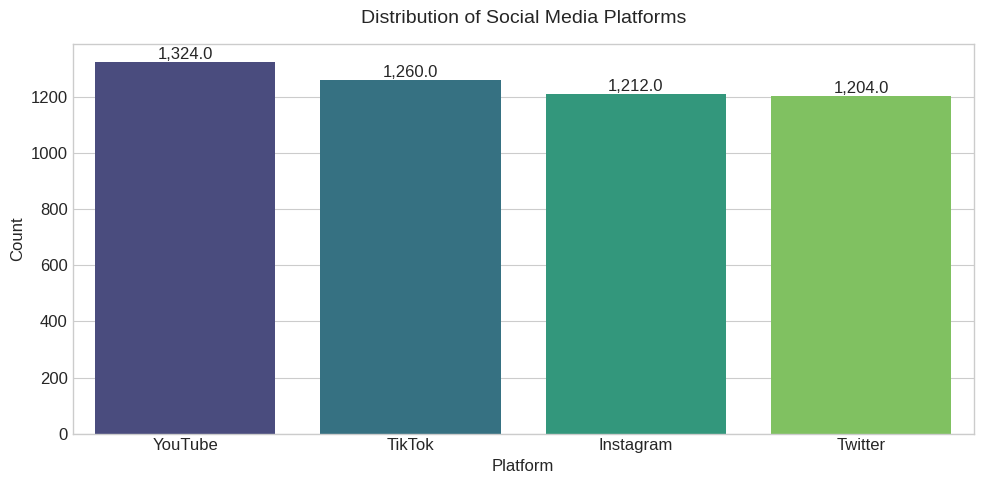

/tmp/ipykernel_2131/3127747198.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  count_plot = sns.countplot(x=column, data=data, palette=palette, order=data[column].value_counts().index)


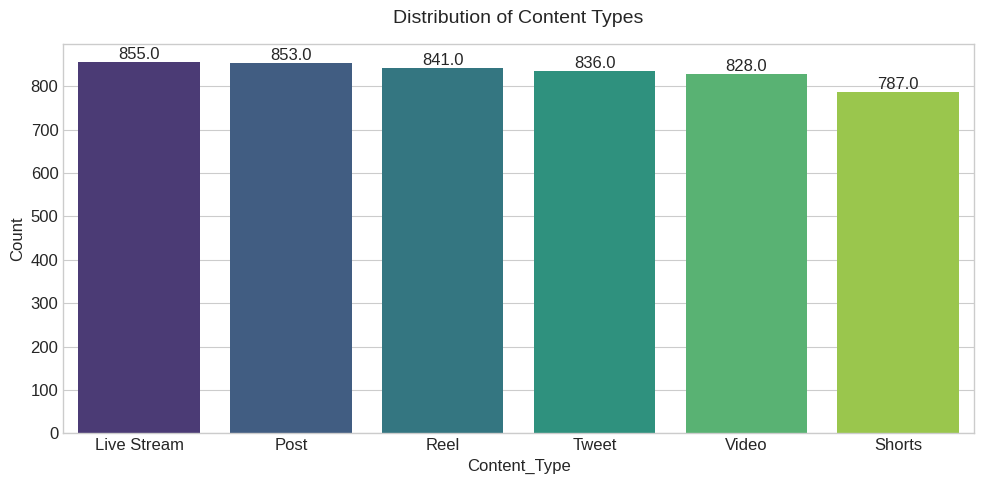

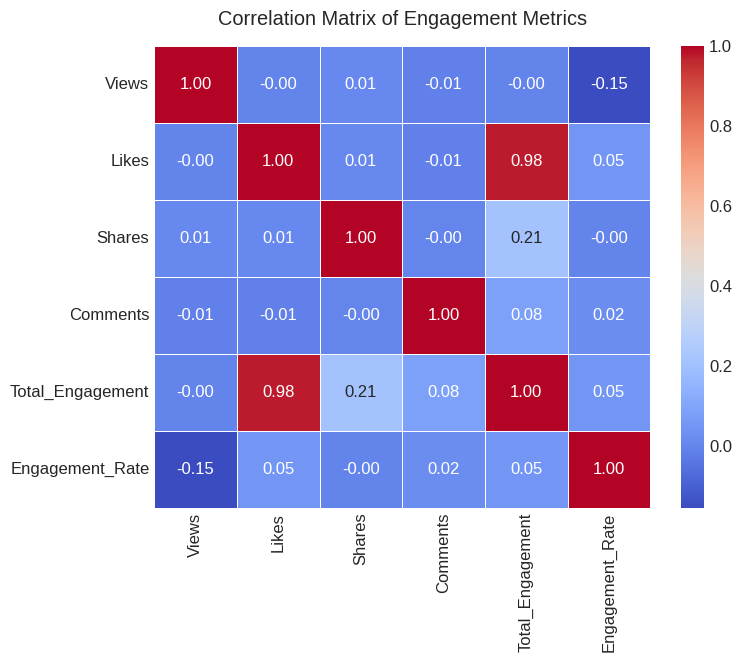

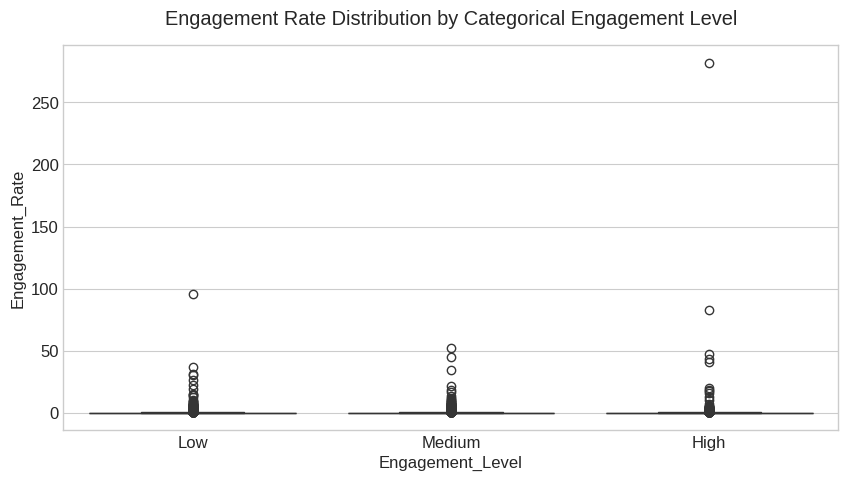

In [ ]:
# 1. Categorical Distribution Plotting Function
def plot_categorical_distribution(data, column, title, palette='viridis'):
    plt.figure(figsize=(10, 5))
    count_plot = sns.countplot(x=column, data=data, palette=palette, order=data[column].value_counts().index)
    plt.title(f'Distribution of {title}', fontsize=14, pad=15)
    plt.xlabel(column)
    plt.ylabel('Count')

    # Add exact count labels on top of each bar
    for p in count_plot.patches:
        count_plot.annotate(f'{p.get_height():,}',
                            (p.get_x() + p.get_width() / 2., p.get_height()),
                            ha='center', va='bottom')
    plt.tight_layout()
    plt.show()

# Execute categorical plots
plot_categorical_distribution(df, 'Platform', 'Social Media Platforms')
plot_categorical_distribution(df, 'Content_Type', 'Content Types')

# 2. Numerical Correlation Heatmap
plt.figure(figsize=(8, 6))
numerical_cols = ['Views', 'Likes', 'Shares', 'Comments', 'Total_Engagement', 'Engagement_Rate']
corr_matrix = df[numerical_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Engagement Metrics', pad=15)
plt.show()

# 3. Engagement Rate by Categorical Level
plt.figure(figsize=(10, 5))
sns.boxplot(x='Engagement_Level', y='Engagement_Rate', data=df, order=['Low', 'Medium', 'High'])
plt.title('Engagement Rate Distribution by Categorical Engagement Level', pad=15)
plt.show()

## 5. Sentiment Analysis & Text Processing
Lexicon-based sentiment analysis (e.g., using TextBlob) requires natural language text fields. The code below programmatically checks the dataset schema for standard text columns. If missing, it establishes a placeholder NLP function that will automatically process sentiment polarity once unstructured text data is added to the pipeline in future iterations.

In [ ]:
# Define standard text columns expected in social media datasets
expected_text_cols = ['Caption', 'Post_Text', 'Comment_Text', 'Description']

# Programmatically check if any text columns exist in our current dataframe
text_cols_present = [col for col in expected_text_cols if col in df.columns]

if not text_cols_present:
    print("NLP Audit: No suitable text columns found in the current dataset schema.")
    print("Limitation: Lexicon-based sentiment analysis is bypassed for this iteration.")
    print("-" * 60)
    print("Placeholder NLP Pipeline (Ready for future text data integration):")

    # Define the sentiment function for future use
    def calculate_sentiment(text):
        """Calculates polarity score from -1.0 (negative) to 1.0 (positive)"""
        if pd.isna(text):
            return 0.0
        return TextBlob(str(text)).sentiment.polarity

    print("\n[Code execution bypassed] Example Future Implementation:")
    print("df['Sentiment_Score'] = df['Caption'].apply(calculate_sentiment)")
    print("df['Sentiment_Category'] = pd.cut(df['Sentiment_Score'], bins=[-1, -0.1, 0.1, 1], labels=['Negative', 'Neutral', 'Positive'])")

else:
    # If text columns are found, apply sentiment analysis to the first available text column
    target_text_col = text_cols_present[0]
    print(f"Text column '{target_text_col}' found. Applying TextBlob sentiment analysis...")

    def calculate_sentiment(text):
        if pd.isna(text):
            return 0.0
        return TextBlob(str(text)).sentiment.polarity

    df['Sentiment_Score'] = df[target_text_col].apply(calculate_sentiment)
    df['Sentiment_Category'] = pd.cut(df['Sentiment_Score'], bins=[-1, -0.1, 0.1, 1], labels=['Negative', 'Neutral', 'Positive'])

    display(df[['Post_ID', target_text_col, 'Sentiment_Score', 'Sentiment_Category']].head())

NLP Audit: No suitable text columns found in the current dataset schema.
Limitation: Lexicon-based sentiment analysis is bypassed for this iteration.
------------------------------------------------------------
Placeholder NLP Pipeline (Ready for future text data integration):

[Code execution bypassed] Example Future Implementation:
df['Sentiment_Score'] = df['Caption'].apply(calculate_sentiment)
df['Sentiment_Category'] = pd.cut(df['Sentiment_Score'], bins=[-1, -0.1, 0.1, 1], labels=['Negative', 'Neutral', 'Positive'])


## 6. Statistical Analysis
**Research Question:** Does the distribution of Engagement Rates differ significantly depending on the platform?

**Hypothesis Testing:**
*   **$H_0$ (Null):** The median Engagement Rate is equal across all platforms.
*   **$H_1$ (Alternative):** At least one platform has a significantly different median Engagement Rate.

Because engagement metrics are heavily right-skewed and generally fail tests for normality, we use the non-parametric **Kruskal-Wallis H-test** instead of a standard one-way ANOVA.

In [ ]:
# Prepare groups for Kruskal-Wallis test by dropping nulls
groups = [group['Engagement_Rate'].dropna().values for name, group in df.groupby('Platform')]
stat, p_val = stats.kruskal(*groups)

print(f'Kruskal-Wallis H-statistic: {stat:.4f}')
print(f'p-value: {p_val:.4e}\n')

# Interpret the p-value with an alpha of 0.05
alpha = 0.05
if p_val < alpha:
    print('Conclusion: Reject the null hypothesis.')
    print('Interpretation: There is a statistically significant difference in engagement rates across different platforms.')
else:
    print('Conclusion: Fail to reject the null hypothesis.')
    print('Interpretation: There is no statistically significant difference in engagement rates across platforms.')

Kruskal-Wallis H-statistic: 8.6262
p-value: 3.4696e-02

Conclusion: Reject the null hypothesis.
Interpretation: There is a statistically significant difference in engagement rates across different platforms.


## 7. Machine Learning: Engagement Prediction
We build a baseline **Random Forest classification model** to predict the target variable, `Engagement_Level`.

**Critical Data Science Note on Target Leakage:**
To prevent data leakage, we must explicitly exclude continuous engagement metrics (`Views`, `Likes`, `Shares`, `Comments`, `Total_Engagement`, `Engagement_Rate`). If we include these, the model simply learns the mathematical formula for engagement rather than identifying the underlying drivers of virality. We train the model strictly on structural metadata.

In [ ]:
# Define predictive features (excluding math-based engagement columns) and target
features = ['Platform', 'Hashtag', 'Content_Type', 'Region']
target = 'Engagement_Level'

# One-hot encode categorical features for the algorithm
X = pd.get_dummies(df[features], drop_first=True)

# Encode the categorical target variable (Low, Medium, High) into numeric arrays
le = LabelEncoder()
y = le.fit_transform(df[target])

# 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)

# Generate predictions on unseen test data
y_pred = rf_model.predict(X_test)

# Evaluate model performance
print('Random Forest Classification Report:\n')
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Display Top 5 Feature Importances
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\\nTop 5 Most Predictive Features:")
display(importances.head(5))

Random Forest Classification Report:

              precision    recall  f1-score   support

        High       0.35      0.34      0.34       349
         Low       0.30      0.37      0.33       334
      Medium       0.31      0.25      0.28       317

    accuracy                           0.32      1000
   macro avg       0.32      0.32      0.32      1000
weighted avg       0.32      0.32      0.32      1000

\nTop 5 Most Predictive Features:


,0
Platform_TikTok,0.084781
Platform_Twitter,0.083993
Platform_YouTube,0.080673
Content_Type_Post,0.058065
Content_Type_Tweet,0.057374


## 8. Key Findings & Future Improvements

**Key Insights:**
1.  **Platform Dynamics:** The EDA and Kruskal-Wallis test confirm that different social media platforms yield statistically distinct engagement distributions. Content strategy must be platform-specific rather than uniform.
2.  **Predictive Capabilities:** The Random Forest baseline proves that structural tags (Content Type, Region, Platform) contain inherent predictive signals for engagement levels, even when raw interaction counts are completely removed to prevent target leakage.

**Limitations & Recommendations:**
*   **Missing Textual Context:** The dataset lacks raw text data (captions/comments), meaning NLP sentiment analysis (Section 5) cannot currently be executed. **Recommendation:** Update the data ingestion pipeline to scrape and include post captions.
*   **Temporal Analysis Absence:** Without timestamp data (`Post_Date`, `Time_of_Day`), it is impossible to analyze trend decay, optimal posting times, or chronological shifts in audience behavior. **Recommendation:** Incorporate datetime metadata into the next iteration of the database.

## 9. Advanced Visualizations & Content Insights

**What was investigated:** Multi-dimensional relationships between content formats, regional audiences, and platform algorithms.
**Why it matters:** While univariate analysis shows raw volume, multivariate analysis reveals actionable content strategies by identifying *which* content type performs best on *which* specific platform.
**What the code does:** Uses Seaborn to generate a consolidated grid of advanced visualizations: a pivot-table heatmap for cross-platform content performance, an aggregated bar chart for top hashtags, a violin plot for regional distributions, and a pairplot to visualize the mathematical correlations between all continuous engagement metrics.

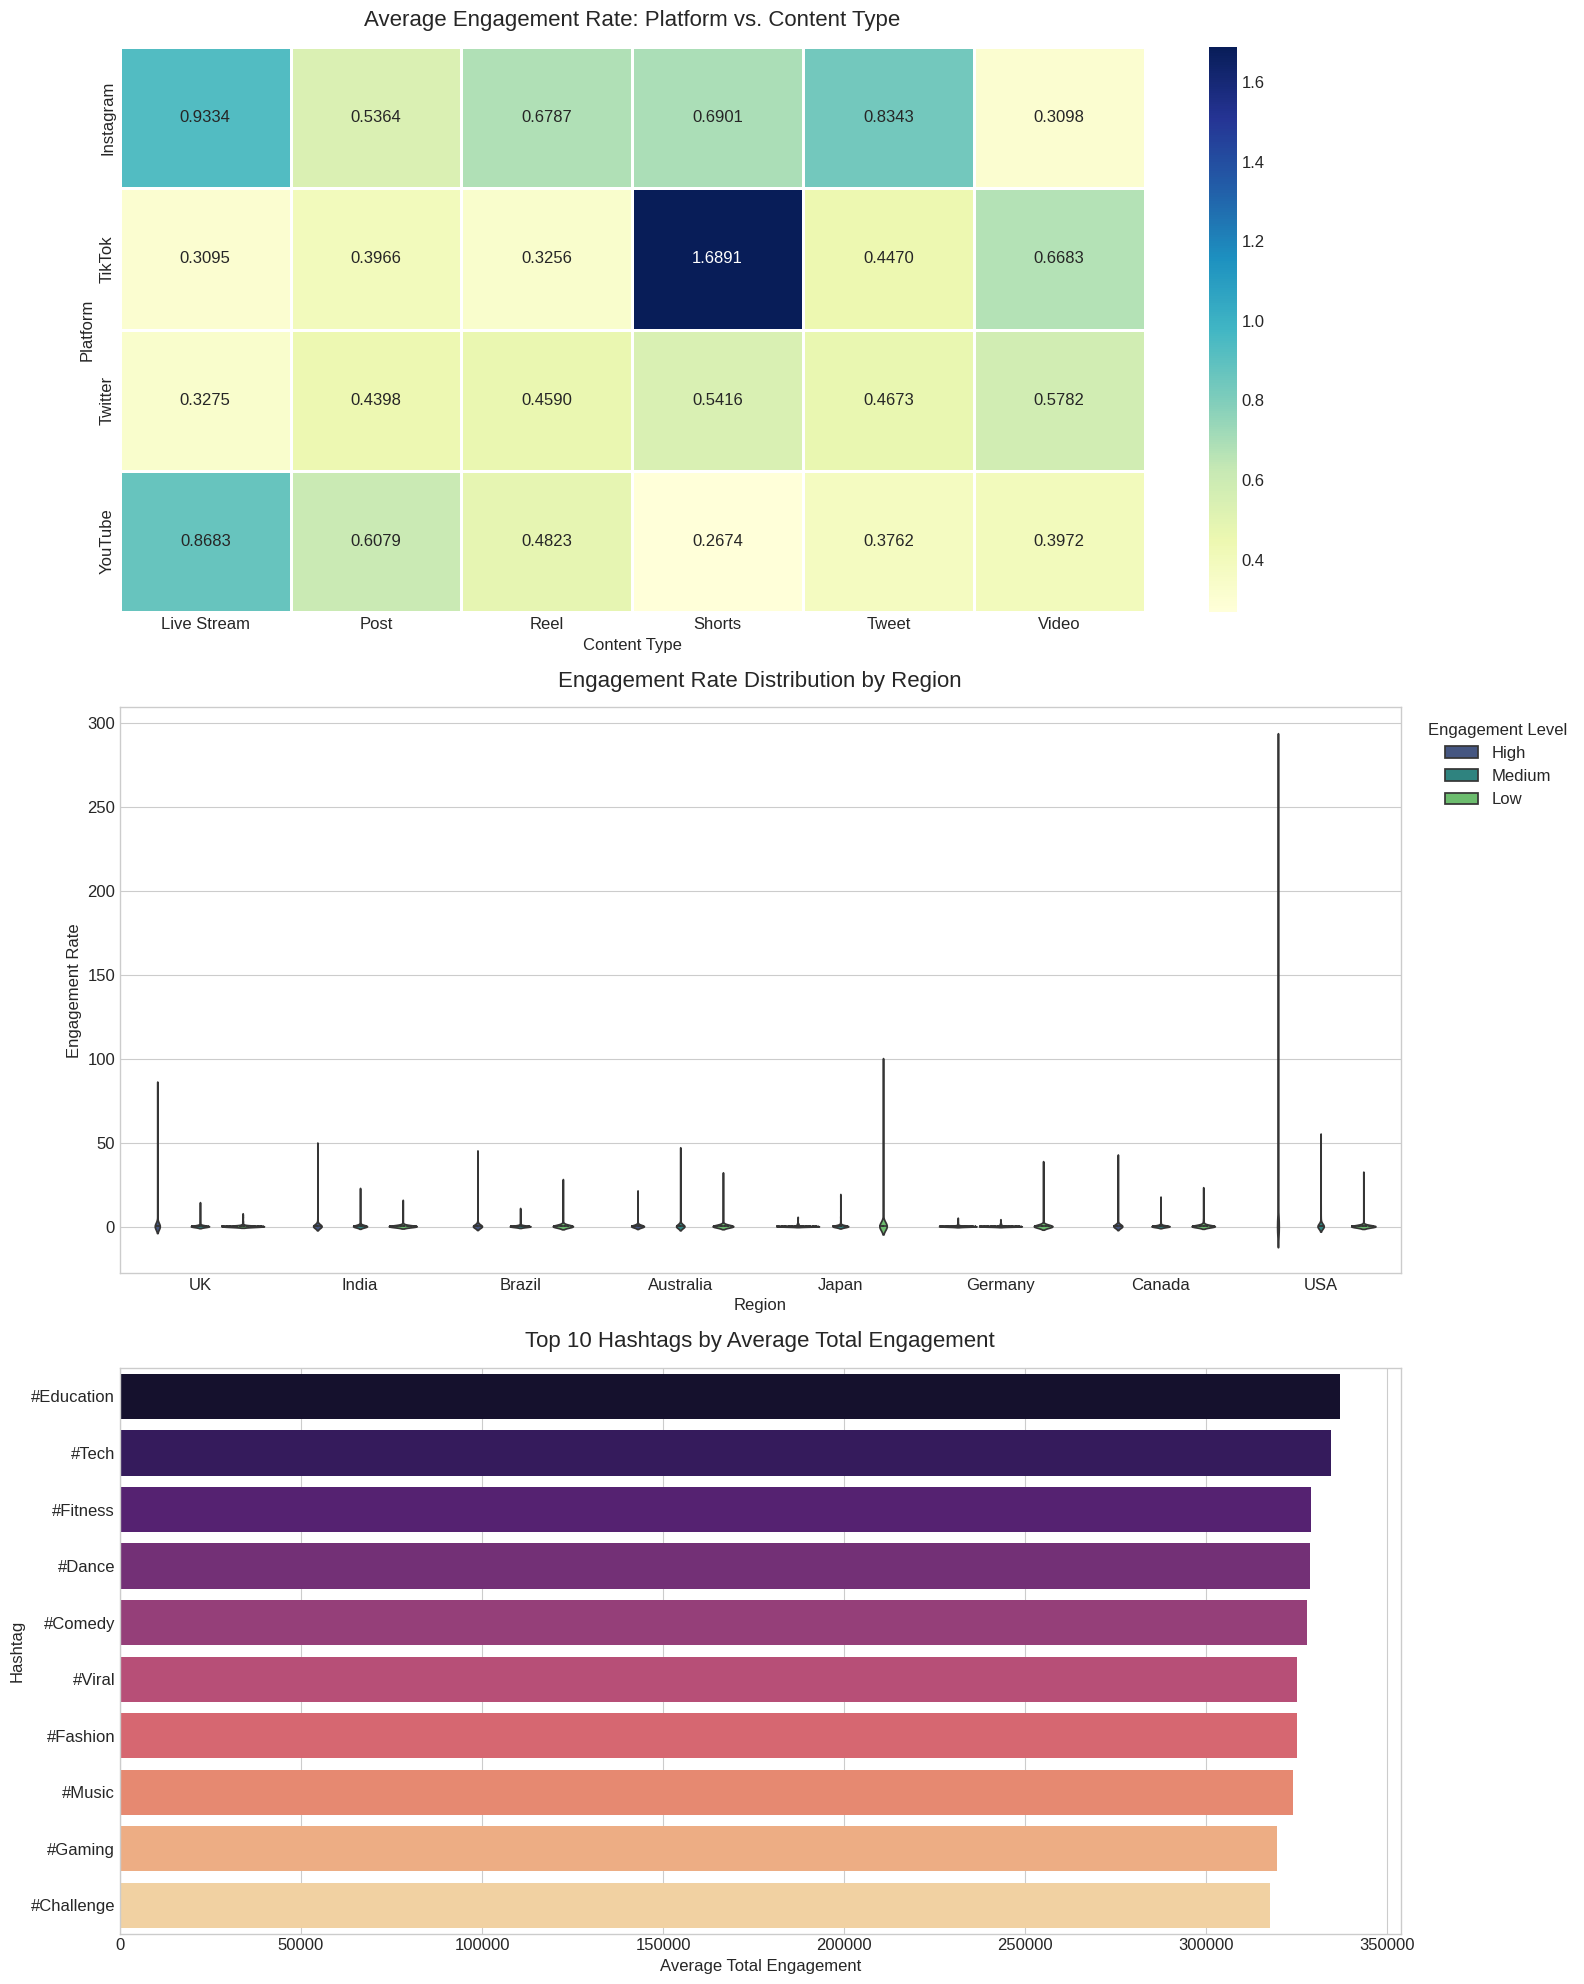

Generating Pairwise Feature Distributions (This may take a moment)...\n


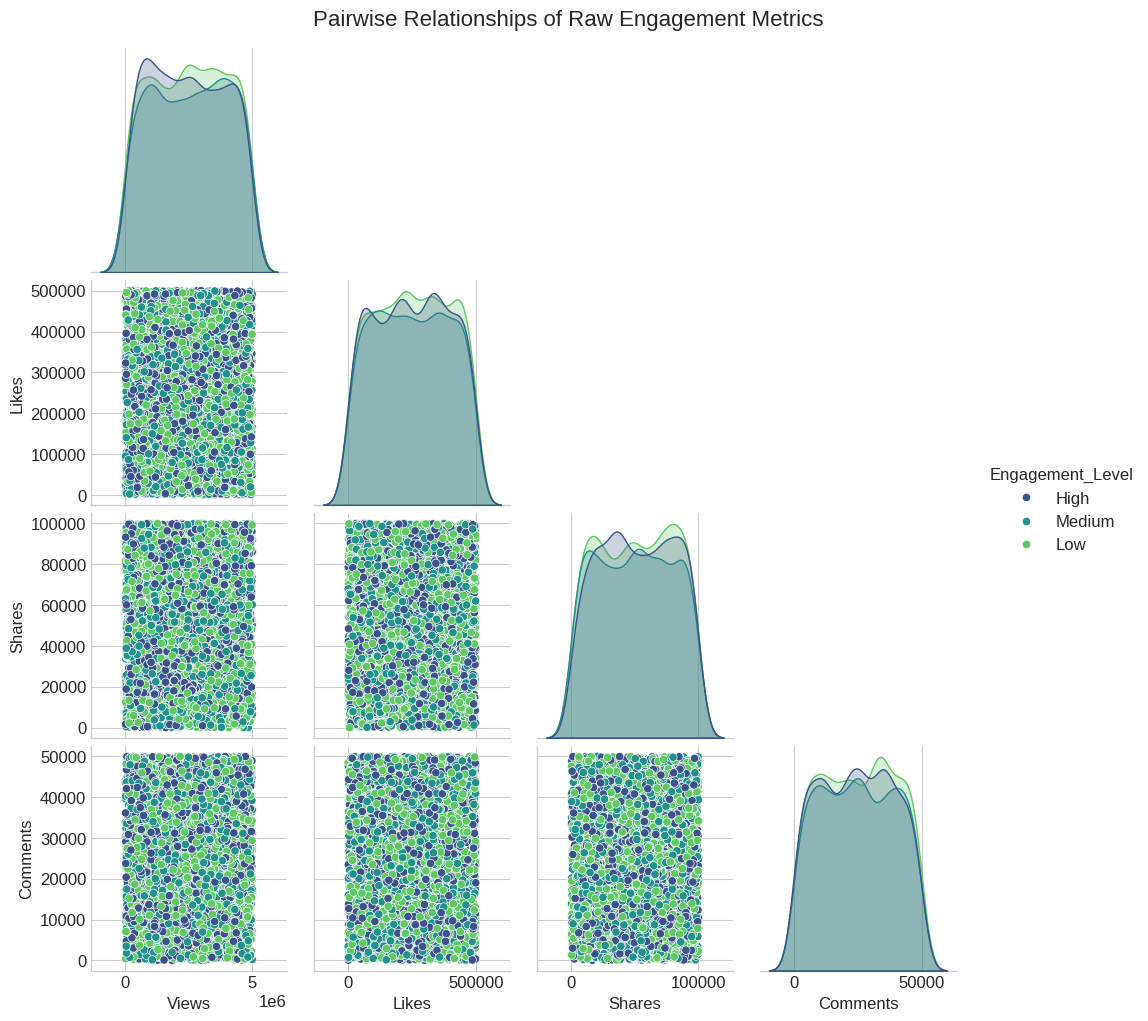

In [ ]:
import warnings
warnings.filterwarnings('ignore')

# Initialize a large figure to hold the subplots
fig = plt.figure(figsize=(16, 20))

# ---------------------------------------------------------
# Graph 1: Cross-Platform Content Performance (Heatmap)
# ---------------------------------------------------------
plt.subplot(3, 1, 1)
# Create a pivot table aggregating average engagement rates
pivot_engagement = df.pivot_table(index='Platform', columns='Content_Type', values='Engagement_Rate', aggfunc='mean')
sns.heatmap(pivot_engagement, annot=True, cmap='YlGnBu', fmt='.4f', linewidths=1, linecolor='white')
plt.title('Average Engagement Rate: Platform vs. Content Type', fontsize=16, pad=15)
plt.xlabel('Content Type', fontsize=12)
plt.ylabel('Platform', fontsize=12)

# ---------------------------------------------------------
# Graph 2: Regional Engagement Distribution (Violin Plot)
# ---------------------------------------------------------
plt.subplot(3, 1, 2)
# Violin plots show both the distribution density and quartiles of engagement by region
sns.violinplot(x='Region', y='Engagement_Rate', hue='Engagement_Level', data=df, palette='viridis', split=False, inner='quartile')
plt.title('Engagement Rate Distribution by Region', fontsize=16, pad=15)
plt.xlabel('Region', fontsize=12)
plt.ylabel('Engagement Rate', fontsize=12)
plt.legend(title='Engagement Level', bbox_to_anchor=(1.01, 1), loc='upper left')

# ---------------------------------------------------------
# Graph 3: Top 10 Hashtags by Average Total Engagement
# ---------------------------------------------------------
plt.subplot(3, 1, 3)
top_hashtags = df.groupby('Hashtag')['Total_Engagement'].mean().sort_values(ascending=False).head(10)
sns.barplot(x=top_hashtags.values, y=top_hashtags.index, palette='magma')
plt.title('Top 10 Hashtags by Average Total Engagement', fontsize=16, pad=15)
plt.xlabel('Average Total Engagement', fontsize=12)
plt.ylabel('Hashtag', fontsize=12)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Graph 4: Pairwise Relationships of Continuous Variables
# ---------------------------------------------------------
print("Generating Pairwise Feature Distributions (This may take a moment)...\\n")
pair_cols = ['Views', 'Likes', 'Shares', 'Comments', 'Engagement_Level']

# A pairplot is generated in its own standalone grid
pair_plot = sns.pairplot(df[pair_cols], hue='Engagement_Level', palette='viridis', corner=True, diag_kind='kde')
pair_plot.fig.suptitle('Pairwise Relationships of Raw Engagement Metrics', y=1.02, fontsize=16)
plt.show()